# NLP Assignment 1 — Amharic N-gram Language Models
Addis Ababa University · Corpus: GPAC (Gereme et al., *Information* 12(1):20, 2021)

| Task | Part |
|---|---|
| #1 N-gram model (1.1–1.8) | 1 |
| #2 Intrinsic evaluation | 2 |
| #3 Extrinsic evaluation | 3 |
| #4 Next-word suggestion | 4 |

Code: `amharic_lm/` (n-grams stored as 64-bit hashes in sorted numpy arrays).

In [1]:
import gc, json, os, sys, time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from amharic_lm.text import normalize, sentences, tokenize, STOPWORDS
from amharic_lm.ngram import NgramLM, Vocab, BOS, EOS, UNK
from amharic_lm import corpus as C
from amharic_lm import evaluate as E

DATA, OUT, FIG = ROOT / "data", ROOT / "outputs", ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
FONT = "/usr/share/fonts/truetype/noto/NotoSansEthiopic-Regular.ttf"
font_manager.fontManager.addfont(FONT)
plt.rcParams["font.family"] = ["DejaVu Sans", "Noto Sans Ethiopic"]  # Latin/math first, Ethiopic as fallback
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 80)
RESULTS = {}
T0 = time.time()

def save_results():
    with open(OUT / "results.json", "w", encoding="utf-8") as f:
        json.dump(RESULTS, f, ensure_ascii=False, indent=1, default=float)

---
# Part 1 — N-gram language model
## 1.1 Preprocessing and corpus statistics
NFC → homophone normalization (ሐ/ኀ→ሀ, ሠ→ሰ, ዐ→አ, ፀ→ጸ) → sentence split on `።` `፡፡` `፧` `?` `!` → tokenize (punctuation removed, numbers → `<NUM>`, Latin dropped).

In [2]:
RAW, CLEAN = DATA / "GPAC.txt", DATA / "gpac_clean.txt"
if not CLEAN.exists() or not (OUT / "raw_stats.json").exists():
    raw_stats = C.preprocess_file(RAW, CLEAN)
    json.dump(raw_stats, open(OUT / "raw_stats.json", "w"))
raw_stats = json.load(open(OUT / "raw_stats.json"))

# example of the pipeline on raw text
sample_raw = open(RAW, encoding="utf-8").read(700)
print("RAW :", sample_raw[:300], "...\n")
for s in list(sentences(sample_raw))[:4]:
    print("SENT:", s)

RAW :     ምን መሰላችሁ? (አንባቢያን) ኢትዮጵያ በተደጋጋሚ ጥሪው ደርሷት ልትታደመው ያልቻለችው የአለም የእግር ኳስ ዋ ለ19ኛ ጊዜ በደቡብ አፍሪካ ሲጠጣ፣ በሩቅ እያየች አንጀቷ ባረረ ልክ በአመቱ በለስ ቀናትና ሌላ ዋ ልትታደም ሁለት ልጆቿን ወደ ደቡብ አፍሪካ ላከች፡፡6ኛው ቢግ ብራዘርስ አፍሪካ አብሮ የመኖር ውድድር በደቡብ አፍሪካ ተካሂዷል፡፡ ከተለያዩ 14 የአፍሪካ አገራት የተውጣጡ 26 ያህል ተሳታፊዎች የተካፈሉበት ይህ ውድድር፣ ግለሰቦች በፈታኝ ሁኔታ ውስጥ በማለፍ  ...

SENT: ['ምን', 'መሰላችሁ']
SENT: ['አንባቢያን', 'ኢትዮጵያ', 'በተደጋጋሚ', 'ጥሪው', 'ደርሷት', 'ልትታደመው', 'ያልቻለችው', 'የአለም', 'የእግር', 'ኳስ', 'ዋ', 'ለ', '<NUM>', 'ኛ', 'ጊዜ', 'በደቡብ', 'አፍሪካ', 'ሲጠጣ', 'በሩቅ', 'እያየች', 'አንጀቷ', 'ባረረ', 'ልክ', 'በአመቱ', 'በለስ', 'ቀናትና', 'ሌላ', 'ዋ', 'ልትታደም', 'ሁለት', 'ልጆቿን', 'ወደ', 'ደቡብ', 'አፍሪካ', 'ላከች']
SENT: ['<NUM>', 'ኛው', 'ቢግ', 'ብራዘርስ', 'አፍሪካ', 'አብሮ', 'የመኖር', 'ውድድር', 'በደቡብ', 'አፍሪካ', 'ተካሂዷል']
SENT: ['ከተለያዩ', '<NUM>', 'የአፍሪካ', 'አገራት', 'የተውጣጡ', '<NUM>', 'ያህል', 'ተሳታፊዎች', 'የተካፈሉበት', 'ይህ', 'ውድድር', 'ግለሰቦች', 'በፈታኝ', 'ሁኔታ', 'ውስጥ', 'በማለፍ', 'ብቃታቸውን', 'የሚያስመሰክሩበት', 'መሆኑን', 'ሰምተናል']


In [3]:
word_counts = C.count_words(CLEAN)
sent_lens = np.array([len(l.split()) for l in open(CLEAN, encoding="utf-8")])
n_tokens, n_types = int(sent_lens.sum()), len(word_counts)
n_unique_sents = len({hash(l) for l in open(CLEAN, encoding="utf-8")})
hapax = sum(1 for c in word_counts.values() if c == 1)
char_lens = np.array([len(w) for w in word_counts for _ in range(1)])
avg_word_len_tok = sum(len(w) * c for w, c in word_counts.items()) / n_tokens

stats = {
    "Raw file size (MB)": os.path.getsize(RAW) / 1e6,
    "Raw characters": raw_stats["raw_chars"],
    "Raw whitespace tokens": raw_stats["raw_ws_tokens"],
    "Sentences": len(sent_lens),
    "Unique sentences": n_unique_sents,
    "Repeated sentences (%)": 100 * (1 - n_unique_sents / len(sent_lens)),
    "Tokens (after cleaning)": n_tokens,
    "Vocabulary size (types)": n_types,
    "Type/token ratio": n_types / n_tokens,
    "Hapax legomena (freq = 1)": hapax,
    "Hapax % of vocabulary": 100 * hapax / n_types,
    "Mean sentence length (tokens)": sent_lens.mean(),
    "Median sentence length": float(np.median(sent_lens)),
    "Max sentence length": int(sent_lens.max()),
    "Mean word length (chars, by token)": avg_word_len_tok,
    "Mean word length (chars, by type)": char_lens.mean(),
    "<NUM> tokens": word_counts["<NUM>"],
    "Stop-word tokens (%)": 100 * sum(word_counts[w] for w in STOPWORDS) / n_tokens,
}
RESULTS["corpus_stats"] = stats
display(pd.DataFrame({"value": stats}).style.format("{:,.3f}"))

,value
Raw file size (MB),"1,063.098"
Raw characters,"424,397,739.000"
Raw whitespace tokens,"81,653,055.000"
Sentences,"5,057,938.000"
Unique sentences,"3,818,593.000"
Repeated sentences (%),24.503
Tokens (after cleaning),"77,222,568.000"
Vocabulary size (types),"1,818,474.000"
Type/token ratio,0.024
Hapax legomena (freq = 1),"747,921.000"


,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
word,ነው,<NUM>,ላይ,ውስጥ,ወደ,እና,ጋር,ነበር,ግን,ጊዜ,...,አቶ,እንደ,መንግስት,ቤት,በ,ስራ,ሰው,ሁሉ,ምን,ናቸው
count,1166232,1133725,754668,346534,331101,318864,291523,275013,271507,244114,...,169389,168380,167369,165868,164317,158148,153887,147918,147534,141195
pct,1.510222,1.468127,0.977264,0.448747,0.428762,0.412916,0.37751,0.35613,0.35159,0.316117,...,0.219352,0.218045,0.216736,0.214792,0.212784,0.204795,0.199277,0.191548,0.19105,0.182842


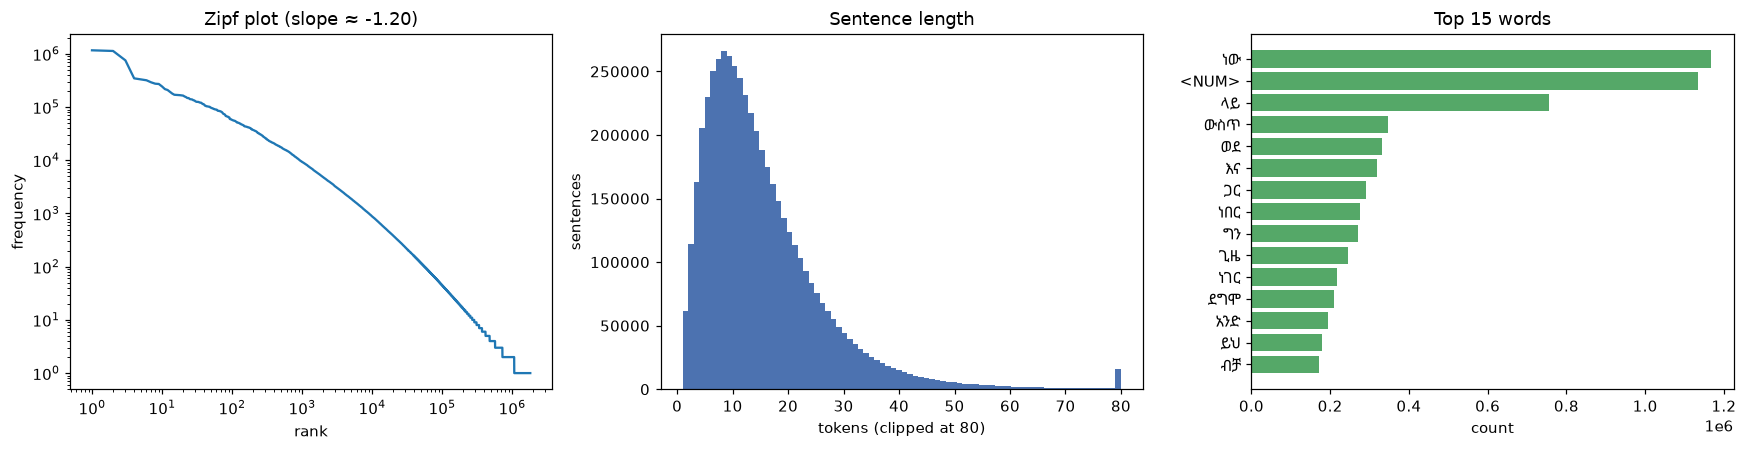

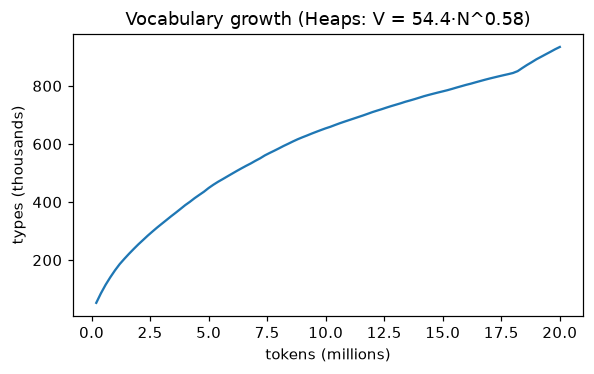

5116

In [4]:
top_words = word_counts.most_common(25)
display(pd.DataFrame(top_words, columns=["word", "count"]).assign(
    pct=lambda d: 100 * d["count"] / n_tokens).T)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
freqs = np.array(sorted(word_counts.values(), reverse=True))
ranks = np.arange(1, len(freqs) + 1)
ax[0].loglog(ranks, freqs, lw=1.5)
slope = np.polyfit(np.log(ranks[10:100000]), np.log(freqs[10:100000]), 1)[0]
ax[0].set(title=f"Zipf plot (slope ≈ {slope:.2f})", xlabel="rank", ylabel="frequency")
ax[1].hist(np.clip(sent_lens, 0, 80), bins=80, color="#4C72B0")
ax[1].set(title="Sentence length", xlabel="tokens (clipped at 80)", ylabel="sentences")
w, c = zip(*top_words[:15])
ax[2].barh(range(15)[::-1], c, color="#55A868")
ax[2].set_yticks(range(15)[::-1], w)
ax[2].set(title="Top 15 words", xlabel="count")
plt.tight_layout(); plt.savefig(FIG / "corpus_stats.png", bbox_inches="tight"); plt.show()

# vocabulary growth (Heaps' law) on the first 20M tokens
seen, growth, n = set(), [], 0
for toks in C.iter_clean(CLEAN):
    for t in toks:
        seen.add(t); n += 1
        if n % 200_000 == 0:
            growth.append((n, len(seen)))
    if n >= 20_000_000:
        break
g = np.array(growth)
b, logk = np.polyfit(np.log(g[:, 0]), np.log(g[:, 1]), 1)
RESULTS["corpus_stats"].update({"Zipf slope": slope, "Heaps beta": b, "Heaps K": float(np.exp(logk))})
plt.figure(figsize=(5.5, 3.5))
plt.plot(g[:, 0] / 1e6, g[:, 1] / 1e3)
plt.title(f"Vocabulary growth (Heaps: V = {np.exp(logk):.1f}·N^{b:.2f})")
plt.xlabel("tokens (millions)"); plt.ylabel("types (thousands)")
plt.tight_layout(); plt.savefig(FIG / "heaps.png", bbox_inches="tight"); plt.show()
del seen; gc.collect()

Large vocabulary and many hapaxes: Amharic attaches prepositions and suffixes to words. About a quarter of sentences are repeats; they are removed before evaluation (Part 2).

## 1.2 Creating n-grams (n = 1–4)
Sentences are padded `<s> <s> <s> w1 … wn </s>`; n-grams never cross sentences.

In [5]:
vocab_full = Vocab.from_counter(word_counts, min_count=1)
full = C.encode(CLEAN, vocab_full)
t = time.time()
lm_full = NgramLM.build(full, vocab_full, order=4, kn=True)
print(f"built in {time.time() - t:.0f}s")

first = open(CLEAN, encoding="utf-8").readline().split()
print("Sentence:", " ".join(first), "\n")
padded = [BOS] * 3 + first + [EOS]
for n in range(1, 5):
    grams = [tuple(padded[i:i + n]) for i in range(len(padded) - n + 1)]
    grams = [g for g in grams if g.count(BOS) <= n - 1 and EOS not in g[:-1]]
    print(f"{n}-grams ({len(grams)}):", ["_".join(g) for g in grams[:8]], "...")

ngram_counts = pd.DataFrame({
    "n": [1, 2, 3, 4],
    "unique n-grams": [len(lm_full.tables[k].keys) for k in range(1, 5)],
    "total n-grams": [int(lm_full.tables[k].count.sum()) for k in range(1, 5)],
    "singletons (%)": [100 * (lm_full.tables[k].count == 1).mean() for k in range(1, 5)],
})
RESULTS["ngram_counts"] = ngram_counts.to_dict("records")
display(ngram_counts.style.format({"unique n-grams": "{:,}", "total n-grams": "{:,}", "singletons (%)": "{:.1f}"}))

  order 1: 1,818,475 unique / 82,280,506 total


  order 2: 23,678,855 unique / 82,280,506 total


  order 3: 44,328,844 unique / 82,280,506 total


  order 4: 52,024,702 unique / 82,280,506 total


built in 104s
Sentence: ምን መሰላችሁ 

1-grams (3): ['ምን', 'መሰላችሁ', '</s>'] ...
2-grams (3): ['<s>_ምን', 'ምን_መሰላችሁ', 'መሰላችሁ_</s>'] ...
3-grams (3): ['<s>_<s>_ምን', '<s>_ምን_መሰላችሁ', 'ምን_መሰላችሁ_</s>'] ...
4-grams (3): ['<s>_<s>_<s>_ምን', '<s>_<s>_ምን_መሰላችሁ', '<s>_ምን_መሰላችሁ_</s>'] ...


,n,unique n-grams,total n-grams,singletons (%)
0,1,"1,818,475","82,280,506",41.1
1,2,"23,678,855","82,280,506",57.8
2,3,"44,328,844","82,280,506",66.7
3,4,"52,024,702","82,280,506",70.3


## 1.3 N-gram probabilities and top-10 n-grams
$P(w_1..w_n) = C(w_1..w_n) / \sum C(\cdot)$

In [6]:
def top_table(lm, n, k=10, skip=(BOS, EOS)):
    rows = lm.top_ngrams(n, k, skip=skip)
    return pd.DataFrame([(" ".join(g), c, p) for g, c, p in rows], columns=[f"{n}-gram", "count", "P"])

RESULTS["top_ngrams"] = {}
for n in range(1, 5):
    df = top_table(lm_full, n)
    RESULTS["top_ngrams"][n] = df.values.tolist()
    display(Markdown(f"**Top 10 {n}-grams**"))
    display(df.style.format({"count": "{:,}", "P": "{:.2e}"}))

**Top 10 1-grams**

,1-gram,count,P
0,ነው,"1,166,232",1.42e-02
1,,"1,133,725",1.38e-02
2,ላይ,"754,668",9.17e-03
3,ውስጥ,"346,534",4.21e-03
4,ወደ,"331,101",4.02e-03
5,እና,"318,864",3.88e-03
6,ጋር,"291,523",3.54e-03
7,ነበር,"275,013",3.34e-03
8,ግን,"271,507",3.30e-03
9,ጊዜ,"244,114",2.97e-03


**Top 10 2-grams**

,2-gram,count,P
0,በ,"135,279",1.64e-03
1,ከ,"107,871",1.31e-03
2,አ ም,"99,372",1.21e-03
3,አ,"92,590",1.13e-03
4,የ,"49,484",6.01e-04
5,ነገር ግን,"44,744",5.44e-04
6,ቀን,"44,236",5.38e-04
7,ቀን,"41,699",5.07e-04
8,ሚሊዮን,"36,806",4.47e-04
9,ኛ,"36,151",4.39e-04


**Top 10 3-grams**

,3-gram,count,P
0,አ ም,"89,581",1.09e-03
1,ቀን,"34,317",4.17e-04
2,ቀን አ,"33,328",4.05e-04
3,በ አ,"27,976",3.40e-04
4,እ ኤ አ,"16,757",2.04e-04
5,ከ በላይ,"12,677",1.54e-04
6,ሚሊዮን ብር,"12,105",1.47e-04
7,አ በ,"10,627",1.29e-04
8,እስከ,"9,978",1.21e-04
9,ከ እስከ,"8,835",1.07e-04


**Top 10 4-grams**

,4-gram,count,P
0,ቀን አ ም,"32,904",4.00e-04
1,ቀን አ,"29,677",3.61e-04
2,በ አ ም,"27,522",3.34e-04
3,ኤ አ በ,"8,640",1.05e-04
4,እ ኤ አ በ,"8,621",1.05e-04
5,ከ እስከ,"7,676",9.33e-05
6,ከ አ ም,"6,256",7.60e-05
7,አ ም ጀምሮ,"5,772",7.02e-05
8,ቀን አም ኢሳት,"5,720",6.95e-05
9,አም ኢሳት ዜና,"5,646",6.86e-05


## 1.4 Conditional probability (bigrams)
$P(w_i \mid w_{i-1}) = C(w_{i-1} w_i) / C(w_{i-1}\,\cdot)$

In [7]:
def cond_prob(prev, w, lm=lm_full):
    V = lm.vocab
    ids, cnt, _ = lm.followers([V.index.get(normalize(prev), V.unk)], 2)
    tot = cnt.sum()
    wid = V.index.get(normalize(w), -1)
    c = int(cnt[ids == wid].sum()) if tot else 0
    return c, int(tot), (c / tot if tot else 0.0)

pairs = [("ኢትዮጵያ", "ውስጥ"), ("አዲስ", "አበባ"), ("ጠቅላይ", "ሚኒስትር"), ("በአፍሪካ", "ቀንድ"),
         ("የቡና", "ምርት"), ("የኢትዮጵያ", "ህዝብ"), ("ብሔራዊ", "ባንክ"), ("ቀንድ", "ትገኛለች")]
df = pd.DataFrame([(a, b, *cond_prob(a, b)) for a, b in pairs],
                  columns=["previous", "word", "C(prev w)", "C(prev ·)", "P(word | previous)"])
RESULTS["conditional"] = df.values.tolist()
display(df.style.format({"P(word | previous)": "{:.4f}"}))

def top_followers(prev, k=6, lm=lm_full):
    V = lm.vocab
    ids, cnt, _ = lm.followers([V.index[normalize(prev)]], 2)
    o = np.argsort(-cnt)[:k]
    return [(V.words[ids[i]], round(cnt[i] / cnt.sum(), 4)) for i in o]

RESULTS["followers"] = {}
for w in ["ኢትዮጵያ", "አዲስ", "የቡና", "ጠቅላይ", "በአፍሪካ"]:
    RESULTS["followers"][w] = top_followers(w)
    print(f"P(· | {w}):", top_followers(w))

,previous,word,C(prev w),C(prev ·),P(word | previous)
0,ኢትዮጵያ,ውስጥ,8185,102553,0.0798
1,አዲስ,አበባ,31453,89283,0.3523
2,ጠቅላይ,ሚኒስትር,19908,41152,0.4838
3,በአፍሪካ,ቀንድ,821,13789,0.0595
4,የቡና,ምርት,246,3900,0.0631
5,የኢትዮጵያ,ህዝብ,12256,113865,0.1076
6,ብሔራዊ,ባንክ,2449,36759,0.0666
7,ቀንድ,ትገኛለች,0,2814,0.0000


P(· | ኢትዮጵያ): [('ውስጥ', np.float64(0.0798)), ('ነገ', np.float64(0.0138)), ('ቡና', np.float64(0.0095)), ('ላይ', np.float64(0.0076)), ('<NUM>', np.float64(0.0072)), ('የጋራ', np.float64(0.0071))]
P(· | አዲስ): [('አበባ', np.float64(0.3523)), ('ዘመን', np.float64(0.0584)), ('ነገር', np.float64(0.0328)), ('አበባን', np.float64(0.0302)), ('አመት', np.float64(0.017)), ('አለም', np.float64(0.013))]
P(· | የቡና): [('ምርት', np.float64(0.0631)), ('ዋጋ', np.float64(0.0359)), ('ቤት', np.float64(0.0287)), ('ግብይት', np.float64(0.0274)), ('መገኛ', np.float64(0.0249)), ('ችግኝ', np.float64(0.0208))]
P(· | ጠቅላይ): [('ሚኒስትር', np.float64(0.4838)), ('ሚኒስትሩ', np.float64(0.1814)), ('ፍርድ', np.float64(0.0467)), ('አቃቤ', np.float64(0.0434)), ('ሚንስትር', np.float64(0.0271)), ('ሚኒስቴር', np.float64(0.0147))]
P(· | በአፍሪካ): [('ህብረት', np.float64(0.0875)), ('ቀንድ', np.float64(0.0595)), ('ውስጥ', np.float64(0.045)), ('ዋንጫ', np.float64(0.0362)), ('ደረጃ', np.float64(0.0315)), ('አህጉር', np.float64(0.021))]


## 1.5 Stop-word removal
163 curated function words plus `<NUM>` are removed; n-grams are rebuilt.

In [8]:
print(f"{len(STOPWORDS)} stop-words, e.g.:", sorted(STOPWORDS)[:30])
sw_counts = C.count_words(CLEAN, remove_stopwords=True)
vocab_sw = Vocab.from_counter(sw_counts, 1)
sw = C.encode(CLEAN, vocab_sw, remove_stopwords=True)
lm_sw = NgramLM.build(sw, vocab_sw, order=4, kn=False)
RESULTS["stopword_tokens_removed"] = int(len(full[0]) - len(sw[0]))
print(f"tokens before: {len(full[0]):,}  after: {len(sw[0]):,}  "
      f"({100 * (1 - len(sw[0]) / len(full[0])):.1f}% removed)")
RESULTS["top_ngrams_nostop"] = {}
for n in range(1, 5):
    df = top_table(lm_sw, n)
    RESULTS["top_ngrams_nostop"][n] = df.values.tolist()
    display(Markdown(f"**Top 10 {n}-grams after stop-word removal**"))
    display(df.style.format({"count": "{:,}", "P": "{:.2e}"}))

163 stop-words, e.g.: ['<NUM>', 'ሁለት', 'ሁሉ', 'ሁሉም', 'ሆነ', 'ሆነው', 'ሆኖ', 'ሆኖም', 'ለ', 'ለምን', 'ለዚህ', 'ሊሆን', 'ላይ', 'ላይም', 'ሌላ', 'ሌሎች', 'ሌሎችም', 'መሆኑ', 'መሆኑን', 'መሆናቸውን', 'መሆን', 'መቼ', 'ማለት', 'ማለትም', 'ማን', 'ማንኛውም', 'ም', 'ምን', 'ምንድነው', 'ምንድን']


  order 1: 1,818,312 unique / 70,031,175 total


  order 2: 24,161,301 unique / 70,031,175 total


  order 3: 40,872,430 unique / 70,031,175 total


  order 4: 45,643,649 unique / 70,031,175 total


...

,2-gram,count,P
0,ቀን አ,"39,491",5.64e-04
1,አዲስ አበባ,"31,458",4.49e-04
2,በአዲስ አበባ,"24,075",3.44e-04
3,ምክር ቤት,"23,888",3.41e-04
4,አለም አቀፍ,"21,294",3.04e-04
5,ጠቅላይ ሚኒስትር,"19,908",2.84e-04
6,የአዲስ አበባ,"19,705",2.81e-04
7,በአሁኑ ወቅት,"18,971",2.71e-04
8,ፍርድ ቤት,"17,533",2.50e-04
9,ኤ አ,"16,902",2.41e-04


**Top 10 3-grams after stop-word removal**

,3-gram,count,P
0,እ ኤ አ,"16,757",2.39e-04
1,ቀን አም ኢሳት,"6,090",8.70e-05
2,አም ኢሳት ዜና,"6,009",8.58e-05
3,ተወካዮች ምክር ቤት,"5,599",8.00e-05
4,በአለም አቀፍ ደረጃ,"5,344",7.63e-05
5,የአዲስ አበባ ከተማ,"4,902",7.00e-05
6,በአዲስ አበባ ከተማ,"4,033",5.76e-05
7,አበባ ከተማ አስተዳደር,"3,951",5.64e-05
8,የእድገትና ትራንስፎርሜሽን እቅድ,"3,796",5.42e-05
9,እ አ አ,"3,768",5.38e-05


**Top 10 4-grams after stop-word removal**

,4-gram,count,P
0,ቀን አም ኢሳት ዜና,"6,007",8.58e-05
1,ቀን አ ኢሳት ዜና,"3,701",5.28e-05
2,የህዝብ ተወካዮች ምክር ቤት,"2,855",4.08e-05
3,የአዲስ አበባ ከተማ አስተዳደር,"2,606",3.72e-05
4,ኦርቶዶክስ ተዋህዶ ቤተ ክርስቲያን,"2,195",3.13e-05
5,የኢትዮጵያ ኦርቶዶክስ ተዋህዶ ቤተ,"1,649",2.35e-05
6,ጠቅላይ ሚኒስትር አብይ አህመድ,"1,594",2.28e-05
7,ጠቅላይ ሚኒስትር መለስ ዜናዊ,"1,327",1.89e-05
8,ወሮበላ የዘራፊ ቡድን ስብስብ,"1,273",1.82e-05
9,ለህዝብ ተወካዮች ምክር ቤት,"1,198",1.71e-05


## 1.6 Word clouds
`<NUM>` stays in the model but is left out of the clouds.

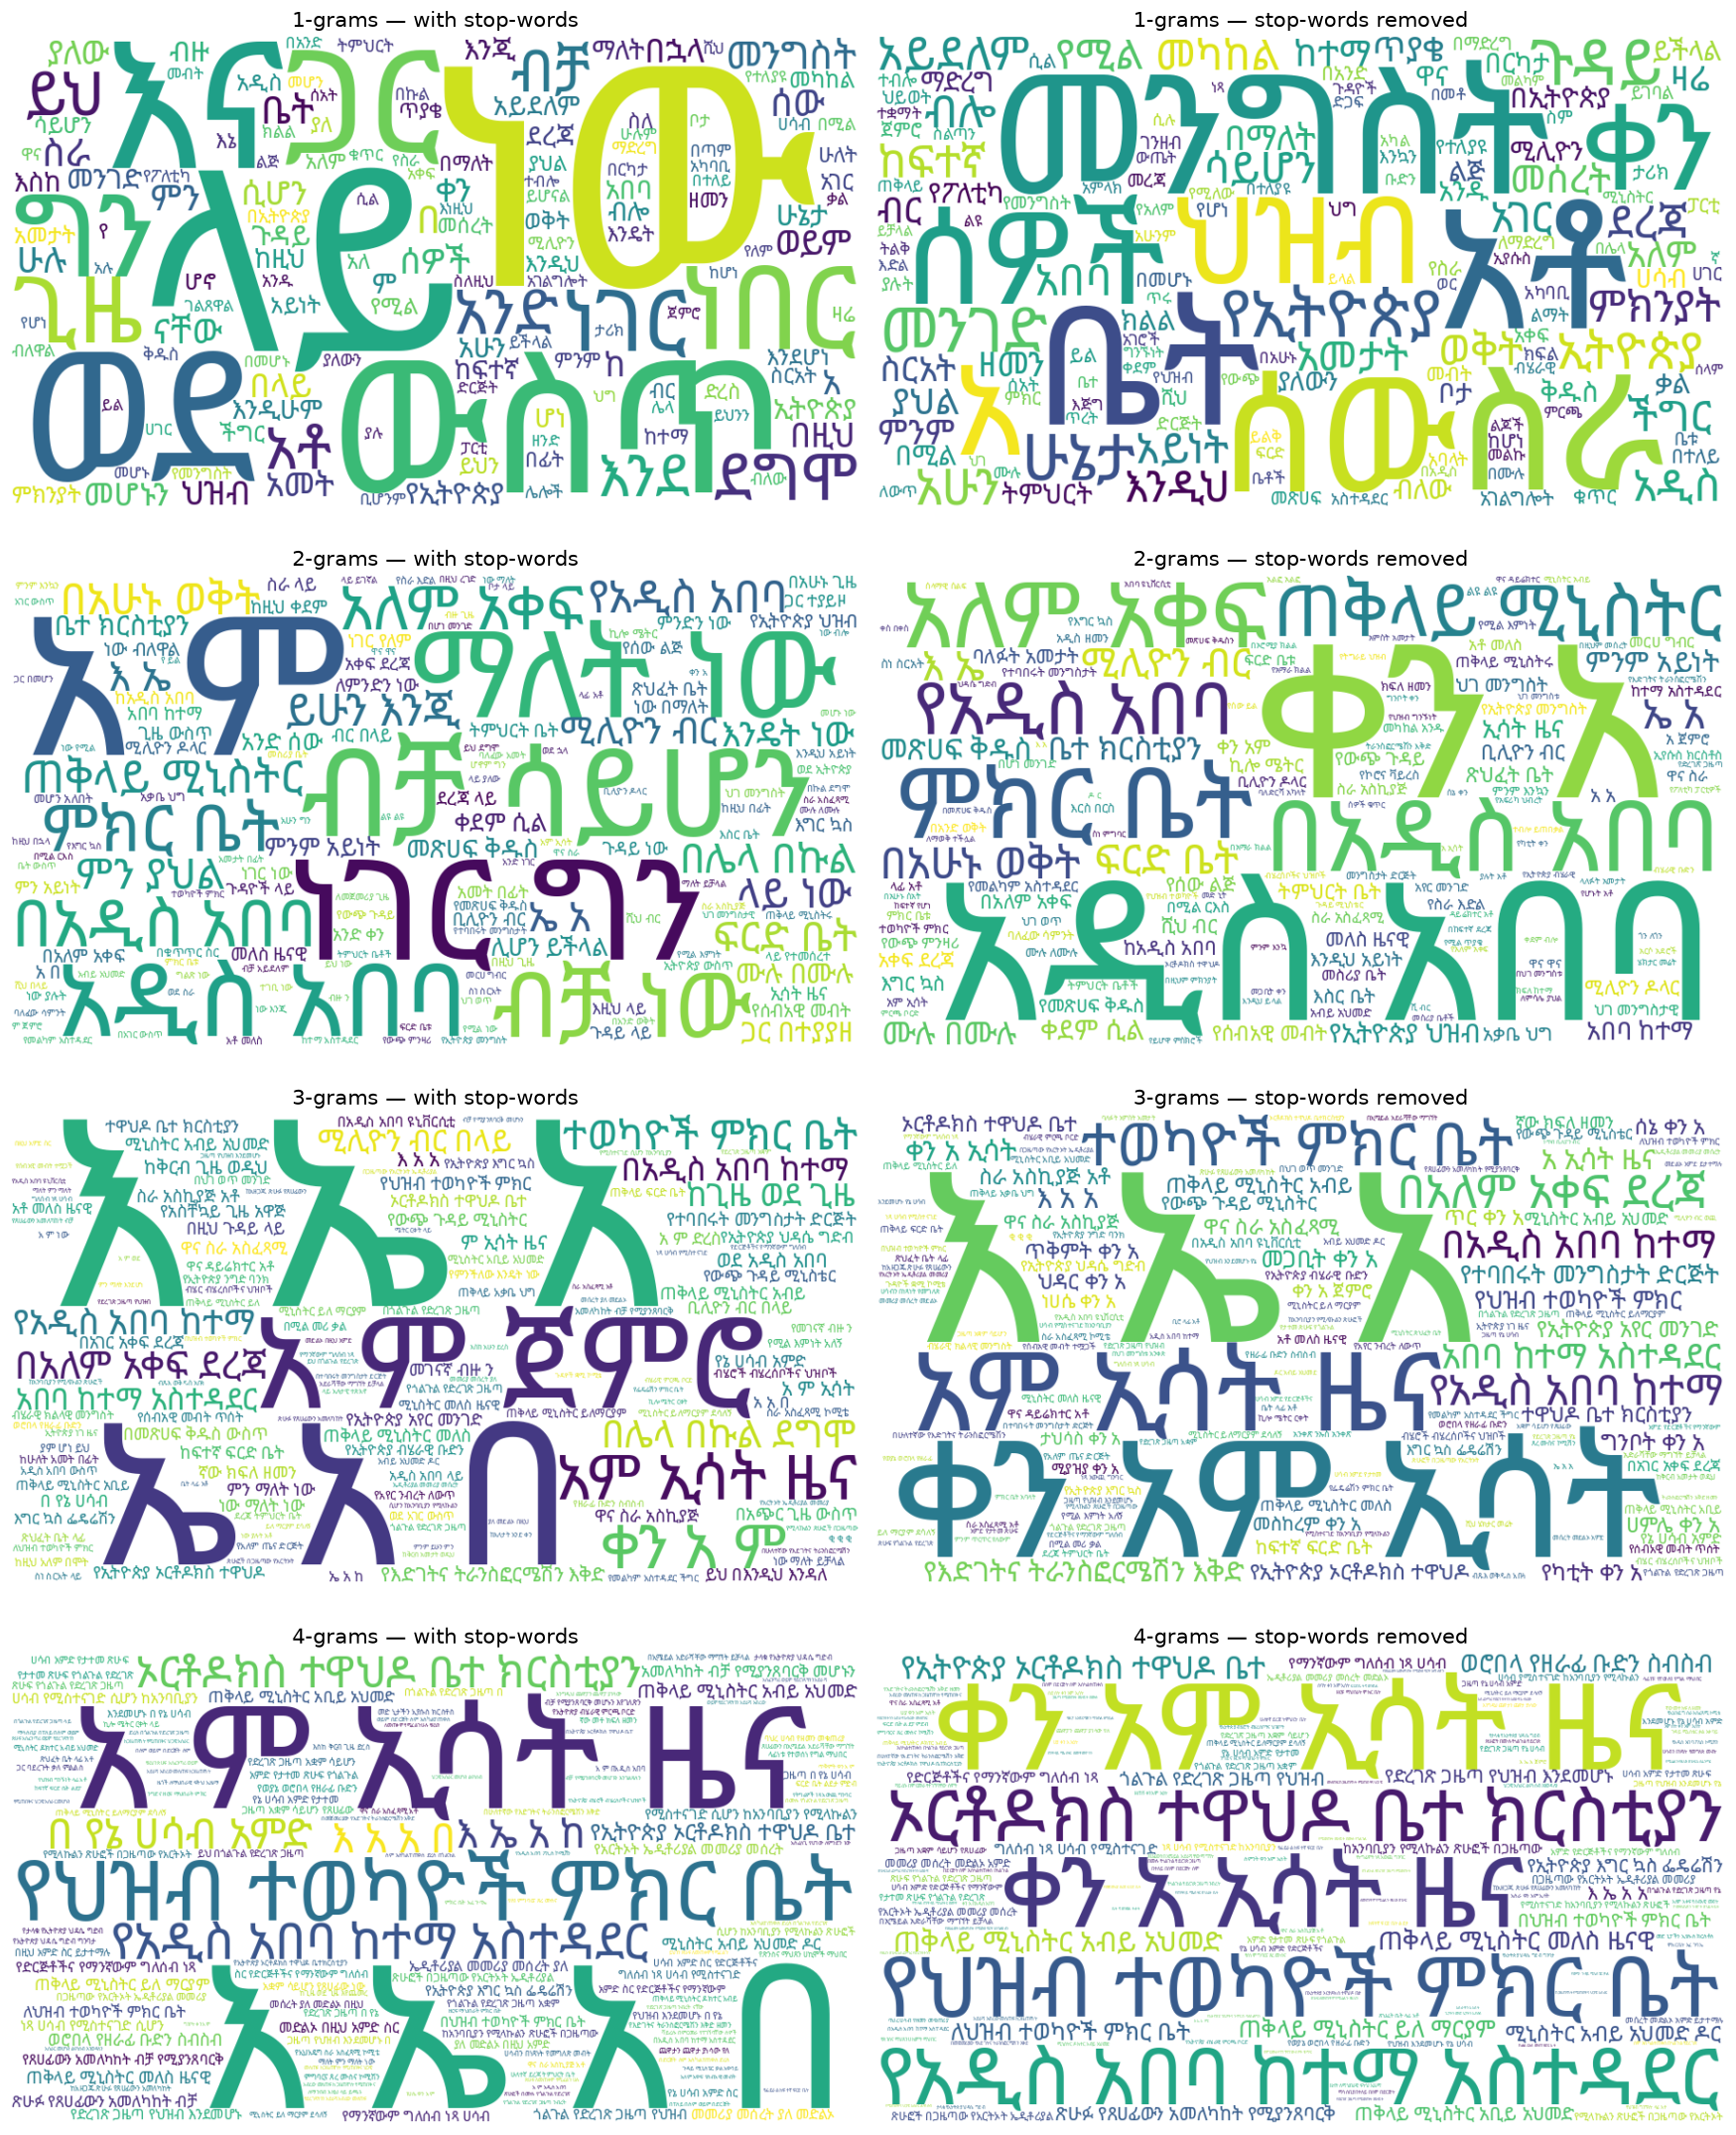

In [9]:
from wordcloud import WordCloud

def cloud(freqs):
    return WordCloud(font_path=FONT, width=900, height=500, background_color="white",
                     colormap="viridis", max_words=150, prefer_horizontal=1.0,
                     regexp=r"\S+", collocations=False).generate_from_frequencies(freqs)

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
for n in range(1, 5):
    for j, (lm, title) in enumerate([(lm_full, "with stop-words"), (lm_sw, "stop-words removed")]):
        freqs = lm.frequencies(n, 150, skip=(BOS, EOS, "<NUM>"))  # words joined by spaces; no <NUM>
        img = cloud(freqs)
        img.to_file(str(FIG / f"wordcloud_{n}gram_{'sw' if j else 'all'}.png"))
        axes[n - 1, j].imshow(img, interpolation="bilinear")
        axes[n - 1, j].set_title(f"{n}-grams — {title}", fontsize=14)
        axes[n - 1, j].axis("off")
plt.tight_layout(); plt.savefig(FIG / "wordclouds.png", bbox_inches="tight", dpi=80); plt.show()

With stop-words: function words dominate. Without: names and topics (አዲስ አበባ, ጠቅላይ ሚኒስትር).

In [10]:
del lm_sw, sw, sw_counts, vocab_sw; gc.collect()

3

## 1.7 Probability of a sentence
$P(w_1..w_m) \approx \prod_i P(w_i \mid w_{i-n+1}..w_{i-1})$, including `</s>`; MLE vs. Kneser-Ney, as log₁₀.

In [11]:
test_sents = ["ኢትዮጵያ በአፍሪካ ቀንድ ትገኛለች።",
              "አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት።",
              "ጠቅላይ ሚኒስትሩ ዛሬ ለፓርላማው ሪፖርት አቀረቡ።",
              "ቡና የኢትዮጵያ ዋነኛ የውጭ ምንዛሪ ምንጭ ነው።",
              "ትገኛለች ቀንድ በአፍሪካ ኢትዮጵያ።"]  # scrambled control

rows = []
for s in test_sents:
    words = next(sentences(s))
    for n in range(1, 5):
        lp_mle, _, _ = lm_full.sentence_logprob(words, n, "mle")
        lp_kn, p, _ = lm_full.sentence_logprob(words, n, "kn")
        rows.append({"sentence": s, "n": n,
                     "log10 P (MLE)": lp_mle / np.log(10),
                     "P (MLE)": np.exp(lp_mle),
                     "log10 P (KN)": lp_kn / np.log(10),
                     "perplexity (KN)": np.exp(-lp_kn / len(p))})
sp = pd.DataFrame(rows)
RESULTS["sentence_probs"] = sp.replace([np.inf, -np.inf], None).values.tolist()
display(sp.style.format({"log10 P (MLE)": "{:.2f}", "P (MLE)": "{:.3e}", "log10 P (KN)": "{:.2f}",
                         "perplexity (KN)": "{:,.1f}"}))

words = next(sentences(test_sents[0]))
_, p_mle, tg = lm_full.sentence_logprob(words, 3, "mle")
_, p_kn, _ = lm_full.sentence_logprob(words, 3, "kn")
ctx = [BOS, BOS] + words
breakdown = pd.DataFrame({"P(w | 2 previous) — trigram": [f"P({w} | {ctx[i]} {ctx[i+1]})" for i, w in enumerate(tg)],
                          "MLE": p_mle, "Kneser-Ney": p_kn})
RESULTS["sentence_breakdown"] = breakdown.values.tolist()
display(breakdown.style.format({"MLE": "{:.4f}", "Kneser-Ney": "{:.4f}"}))

,sentence,n,log10 P (MLE),P (MLE),log10 P (KN),perplexity (KN)
0,ኢትዮጵያ በአፍሪካ ቀንድ ትገኛለች።,1,-16.80,1.579e-17,-16.80,"2,292.5"
1,ኢትዮጵያ በአፍሪካ ቀንድ ትገኛለች።,2,-inf,0.000e+00,-11.56,204.7
2,ኢትዮጵያ በአፍሪካ ቀንድ ትገኛለች።,3,-inf,0.000e+00,-11.05,161.8
3,ኢትዮጵያ በአፍሪካ ቀንድ ትገኛለች።,4,-inf,0.000e+00,-11.10,165.7
4,አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት።,1,-19.78,1.643e-20,-19.78,670.4
5,አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት።,2,-12.63,2.362e-13,-12.60,63.1
6,አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት።,3,-8.54,2.900e-09,-8.48,16.3
7,አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት።,4,-7.11,7.844e-08,-7.06,10.2
8,ጠቅላይ ሚኒስትሩ ዛሬ ለፓርላማው ሪፖርት አቀረቡ።,1,-24.79,1.617e-25,-24.79,"3,480.2"
9,ጠቅላይ ሚኒስትሩ ዛሬ ለፓርላማው ሪፖርት አቀረቡ።,2,-14.63,2.338e-15,-14.68,124.9


,P(w | 2 previous) — trigram,MLE,Kneser-Ney
0,P(ኢትዮጵያ | ),0.0039,0.0040
1,P(በአፍሪካ | ኢትዮጵያ),0.0072,0.0075
2,P(ቀንድ | ኢትዮጵያ በአፍሪካ),0.1657,0.1738
3,P(ትገኛለች | በአፍሪካ ቀንድ),0.0000,0.0000
4,P( | ቀንድ ትገኛለች),0.0000,0.6311


## 1.8 Random sentence generation
Sample each next word from the MLE distribution until `</s>`.

In [12]:
rng = np.random.default_rng(7)
gen = {}
for n in range(1, 5):
    gen[n] = [" ".join(lm_full.generate(n, rng, max_len=30)) for _ in range(4)]
    print(f"\n=== {n}-gram ===")
    for s in gen[n]:
        print(" •", s + " ።")
RESULTS["generated"] = gen


=== 1-gram ===
 • በሚቀጥለው ነው ነውጠኛ በእጃቸው ይደረጋል የማያውቁ ተችግረናል አጥባቂዎችን ከተባለው ተቀጣን አመት አይደለም መኮንን ነጥብ አስተሳሰብ ዋስትና በኢ ወታደራዊና ሶስት የተተካው ሮበርትስ ም አቆጠቀጠር ቁጥር ማለት እንኳን መልካም መሆኑ ደረጃ ለታዳሚው ።
 • ብዝ ማምታታት የሚል የሚነሱትን ።
 • የሚያስችል ከኖርዌይ እንዲሁም ምስራች ማሜ እንዲያውም የሚያልፈው ወረዳ አንድነት ያለው ።
 • ጥናት የኮሮና ከሰሀራ በነፍስ መንፈስ ለ ሰሞኑን እንደታላቅ ትቼ ማድላት ይችላል ቅንጅታዊ በማቋረጡ ከሰጡኝ አብይ ግንኙነት ከአፌ ይሄው በፊት መቀጠል አሰቃቂው አላቸው ደጋፊ አረንቋ አስከባሪ አላት ሙሉ ከመሆኑ በገሀድና እንደሚደገፍ ።

=== 2-gram ===
 • እነዚህ ህገ መንግስታዊ ባልሆነ ምክንያት ሆኖ ለምሳሌ የደቡብ ትግራይንና ተጋሩን ማዳከም የሚለዉን ጥያቄ ማደር ይበጃልና ።
 • የኦሮሚያ ክልል ከሌላው ጋር ተወዳድረው <NUM> ብር <NUM> ኛ ሳምንት ይፋ አድርጓል ።
 • ወደፊት ማራመድ ያሻል ።
 • በአለም ለሚታየው ችግር ሲያጋጥም ወይም ከተበተነ ወዲህ ስርአቱ አላግባብ እየዘረፈና ወደ ሁከት ሳቢያ ተጠያቂ ያለመሆናቸው የሚሉት አቶ አሰፋ አራዳክ ከተማወረዳ <NUM> አምያለ ፕሬስ ዙሪያ በተነሳ ተቃውሞ አሰሙ ኢሳት ዜና መስከረም ።

=== 3-gram ===
 • ግን ያን ያህል የምታሰጋ ልትሆን ባልቻለች ነበር ።
 • ያም ሆኖ ቹንግ ኬዮንና ጁሊ ቅር የሚላቸው ነገር ይኸውም ስልጠና በመስጠት በኢትዮጵያ የተለያዩ የልማት ስትራቴጂዎችን ነድፈን እየሰራን ነው ።
 • ህወሀት ኢህ አዴግ አምባገነን መንግስት ለይስሙላና በተግባር ባዶ የሆነ የቅንጦት ግድብ የፈለገውን ያህል ለውጥ እያስመዘገብን እንደሆነ ስንቶቻችን እናውቅ ይሆን ።
 • በታ

**As n increases:** unigram = random words → bigram = grammatical pairs → trigram = fluent clauses → 4-gram = copies of training sentences (70% of 4-grams are seen once). Fluency up, novelty down.

In [13]:
del lm_full, full; gc.collect()
save_results()

---
# Part 2 — Intrinsic evaluation (perplexity)
Deduplicate sentences → 98% train / 2% test (seed 42) → words seen < 2 times become `<UNK>`.
$PP = \exp\big(-\tfrac{1}{N}\sum \ln P(w_i \mid h_i)\big)$. Compared: MLE, Laplace, add-k (tuned), interpolated Kneser-Ney.

In [14]:
DEDUP = DATA / "gpac_dedup.txt"
seen = set()
with open(CLEAN, encoding="utf-8") as f, open(DEDUP, "w", encoding="utf-8") as out:
    for line in f:
        h = hash(line)
        if h not in seen:
            seen.add(h)
            out.write(line)
del seen; gc.collect()
counts_all = C.count_words(DEDUP)
vocab_all = Vocab.from_counter(counts_all, 1)
enc = C.encode(DEDUP, vocab_all)
(train_raw, test_raw) = C.split(*enc, test_frac=0.02, seed=42)
(train_raw, dev_raw) = C.split(*train_raw, test_frac=0.005, seed=1)
del enc; gc.collect()

# training vocabulary: words seen >= 2 times in train
tr_counts = np.bincount(train_raw[0], minlength=len(vocab_all))
keep_words = [vocab_all.words[i] for i in np.flatnonzero(tr_counts >= 2) if i > 2]
vocab = Vocab([BOS, EOS, UNK] + sorted(keep_words, key=lambda w: -tr_counts[vocab_all.index[w]]))
remap = np.full(len(vocab_all), vocab.unk, np.int32)
remap[[vocab_all.index[w] for w in vocab.words[3:]]] = np.arange(3, len(vocab), dtype=np.int32)
remap[0], remap[1] = 0, 1
train = (remap[train_raw[0]], train_raw[1])
test = (remap[test_raw[0]], test_raw[1])
dev = (remap[dev_raw[0]], dev_raw[1])
del train_raw, test_raw, dev_raw, counts_all; gc.collect()

split_info = {"train sentences": len(train[1]), "train tokens": len(train[0]),
              "dev sentences": len(dev[1]), "test sentences": len(test[1]),
              "test tokens": len(test[0]), "vocabulary (min count 2)": len(vocab),
              "test OOV rate (%)": 100 * float((test[0] == vocab.unk).mean())}
RESULTS["split"] = split_info
display(pd.DataFrame({"value": split_info}).style.format("{:,.2f}"))

t = time.time()
lm = NgramLM.build(train, vocab, order=4, kn=True)
print(f"built in {time.time() - t:.0f}s")

,value
train sentences,"3,723,357.00"
train tokens,"59,848,314.00"
dev sentences,"18,831.00"
test sentences,"76,405.00"
test tokens,"1,230,336.00"
vocabulary (min count 2),"840,861.00"
test OOV rate (%),2.43


  order 1: 840,860 unique / 63,571,671 total


  order 2: 21,695,449 unique / 63,571,671 total


  order 3: 42,758,558 unique / 63,571,671 total


  order 4: 50,608,768 unique / 63,571,671 total


built in 101s


In [15]:
# tune k for add-k on the dev set
dev_l = C.to_lists(dev)
ks = [1.0, 0.1, 0.01, 0.001, 0.0005, 0.0001, 0.00001]
best_k = {}
for n in range(1, 5):
    pps = {k: lm.perplexity(dev_l, n, "addk", k)[0] for k in ks}
    best_k[n] = min(pps, key=pps.get)
    print(f"n={n}: " + "  ".join(f"k={k}: {v:,.0f}" for k, v in pps.items()), "-> best", best_k[n])
RESULTS["best_k"] = best_k

n=1: k=1.0: 10,685  k=0.1: 10,654  k=0.01: 10,652  k=0.001: 10,652  k=0.0005: 10,652  k=0.0001: 10,652  k=1e-05: 10,652 -> best 1e-05


n=2: k=1.0: 39,946  k=0.1: 11,169  k=0.01: 4,367  k=0.001: 2,934  k=0.0005: 2,878  k=0.0001: 3,167  k=1e-05: 4,584 -> best 0.0005


n=3: k=1.0: 262,389  k=0.1: 126,270  k=0.01: 59,178  k=0.001: 31,452  k=0.0005: 27,190  k=0.0001: 21,683  k=1e-05: 21,832 -> best 0.0001


n=4: k=1.0: 420,853  k=0.1: 276,415  k=0.01: 175,088  k=0.001: 115,770  k=0.0005: 103,740  k=0.0001: 83,472  k=1e-05: 69,779 -> best 1e-05


,MLE,MLE: % zero-prob tokens,Laplace (add-1),add-k (tuned),k,Kneser-Ney
n,,,,,,
1,"10,682.2",0.0,"10,714.9","10,682.2",0.0,"10,682.2"
2,inf,24.0,"39,834.2","2,843.1",0.0,"1,219.8"
3,inf,57.8,"262,315.0","21,540.2",0.0,760.0
4,inf,72.6,"420,136.9","69,018.0",0.0,675.9


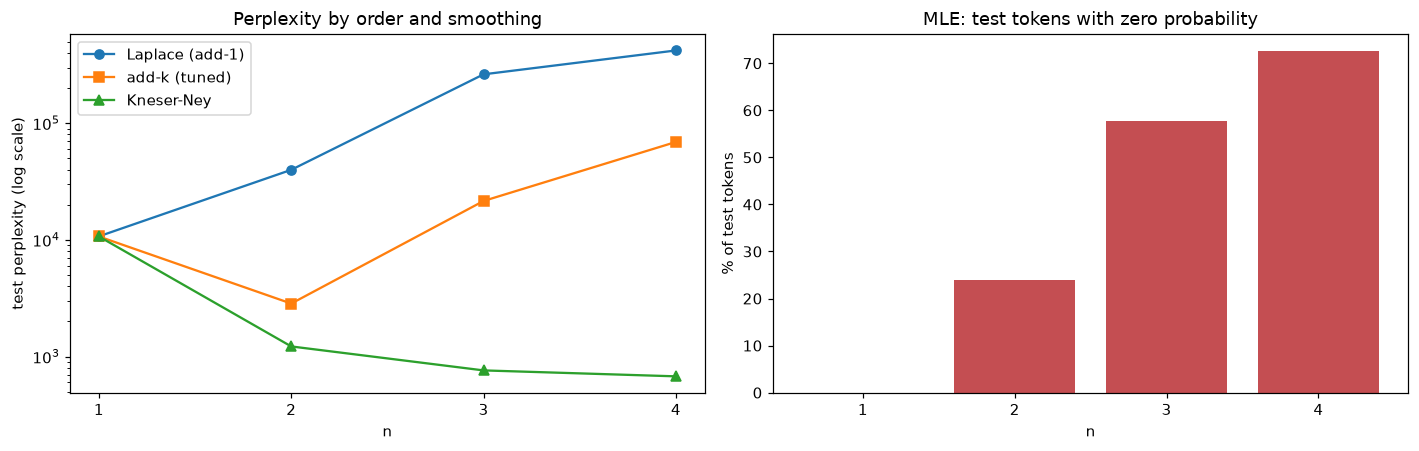

In [16]:
test_l = C.to_lists(test)
rows = []
for n in range(1, 5):
    pp_mle, zero = lm.perplexity(test_l, n, "mle")
    rows.append({"n": n,
                 "MLE": pp_mle, "MLE: % zero-prob tokens": 100 * zero,
                 "Laplace (add-1)": lm.perplexity(test_l, n, "addk", 1.0)[0],
                 f"add-k (tuned)": lm.perplexity(test_l, n, "addk", best_k[n])[0],
                 "k": best_k[n],
                 "Kneser-Ney": lm.perplexity(test_l, n, "kn")[0]})
pp = pd.DataFrame(rows).set_index("n")
RESULTS["perplexity"] = pp.reset_index().replace([np.inf], None).to_dict("records")
display(pp.style.format("{:,.1f}"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for col, m in [("Laplace (add-1)", "o-"), ("add-k (tuned)", "s-"), ("Kneser-Ney", "^-")]:
    ax[0].plot(pp.index, pp[col], m, label=col)
ax[0].set(yscale="log", xticks=[1, 2, 3, 4], xlabel="n", ylabel="test perplexity (log scale)",
          title="Perplexity by order and smoothing")
ax[0].legend()
ax[1].bar(pp.index, pp["MLE: % zero-prob tokens"], color="#C44E52")
ax[1].set(xticks=[1, 2, 3, 4], xlabel="n", ylabel="% of test tokens",
          title="MLE: test tokens with zero probability")
plt.tight_layout(); plt.savefig(FIG / "perplexity.png", bbox_inches="tight"); plt.show()

### Extra: training-set size

,train tokens (M),n=1,n=2,n=3,n=4
0,3.0,"11,243.2","3,049.8","2,826.3","2,857.9"
1,9.0,"10,913.4","2,180.6","1,876.7","1,867.8"
2,23.9,"10,769.6","1,617.9","1,228.7","1,179.3"
3,59.8,"10,682.2","1,219.8",760.0,675.9


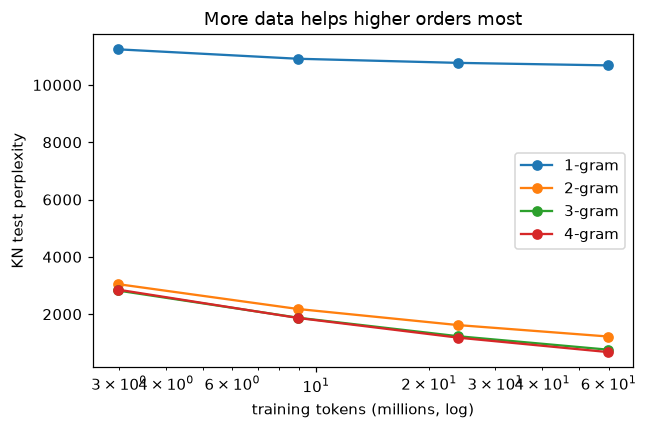

In [17]:
lc = []
for frac in [0.05, 0.15, 0.4]:
    sub = C.subset(train, frac, seed=3)
    m = NgramLM.build(sub, vocab, order=4, kn=True, verbose=False)
    lc.append({"train tokens (M)": len(sub[0]) / 1e6,
               **{f"n={n}": m.perplexity(test_l, n, "kn")[0] for n in range(1, 5)}})
    del m, sub; gc.collect()
lc.append({"train tokens (M)": len(train[0]) / 1e6, **{f"n={n}": pp.loc[n, "Kneser-Ney"] for n in range(1, 5)}})
lc = pd.DataFrame(lc)
RESULTS["learning_curve"] = lc.to_dict("records")
display(lc.style.format("{:,.1f}"))
plt.figure(figsize=(6, 4))
for n in range(1, 5):
    plt.plot(lc["train tokens (M)"], lc[f"n={n}"], "o-", label=f"{n}-gram")
plt.xscale("log"); plt.xlabel("training tokens (millions, log)"); plt.ylabel("KN test perplexity")
plt.title("More data helps higher orders most"); plt.legend()
plt.tight_layout(); plt.savefig(FIG / "learning_curve.png", bbox_inches="tight"); plt.show()
save_results()

**Findings:** MLE gives zero probabilities (∞ perplexity); add-one gets worse with n; Kneser-Ney improves at every order with diminishing returns; higher orders need more data.

---
# Part 3 — Extrinsic evaluation
1. **Next-word prediction**: top-k accuracy and MRR on 5,000 test positions.
2. **Keystroke savings**: simulated keyboard with 5 suggestions.
3. **Real vs. corrupted sentence**: swap / replace / shuffle (chance = 50%).

In [18]:
ext = {}
for n in range(1, 5):
    t = time.time()
    r = {"n": n}
    r.update({f"NWP {k}": v for k, v in E.next_word_prediction(lm, test_l, n, 5000).items()
              if k in ("top1", "top3", "top5", "top10", "mrr@10")})
    r["KSS (top-5)"] = E.keystroke_savings(lm, test_l, n, k=5, max_words=1500)["kss"]
    for kind in ("swap", "replace", "shuffle"):
        r[f"discrim. {kind}"] = E.corruption_discrimination(lm, test_l, n, kind, max_sents=3000)["accuracy"]
    ext[n] = r
    print(f"n={n} done in {time.time() - t:.0f}s")
ext = pd.DataFrame(ext.values()).set_index("n")
RESULTS["extrinsic"] = ext.reset_index().to_dict("records")
display((ext * 100).style.format("{:.1f}"))

n=1 done in 4s


n=2 done in 49s


n=3 done in 82s


n=4 done in 117s


,NWP top1,NWP top3,NWP top5,NWP top10,NWP mrr@10,KSS (top-5),discrim. swap,discrim. replace,discrim. shuffle
n,,,,,,,,,
1,5.5,8.4,9.8,11.4,7.2,37.0,50.0,40.4,50.0
2,15.1,21.7,25.3,31.2,19.6,48.5,89.0,79.5,98.9
3,21.5,29.6,33.3,38.7,26.6,51.7,89.9,79.7,98.8
4,24.4,32.4,35.9,40.3,29.3,52.2,89.7,79.9,98.8


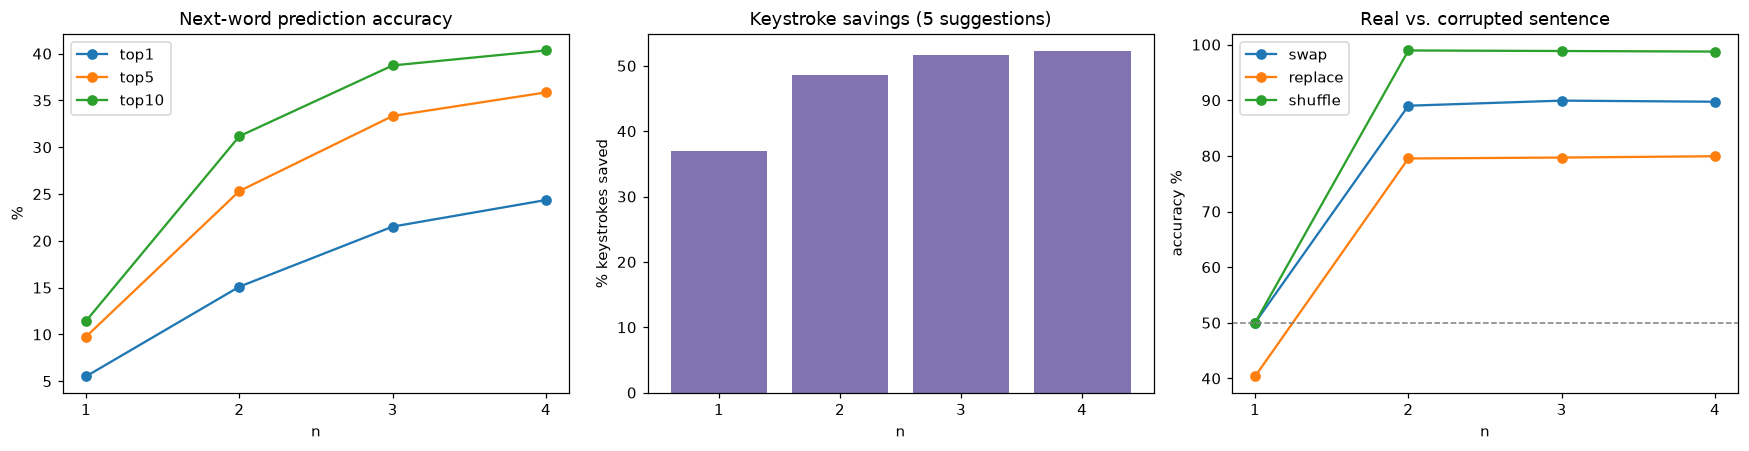

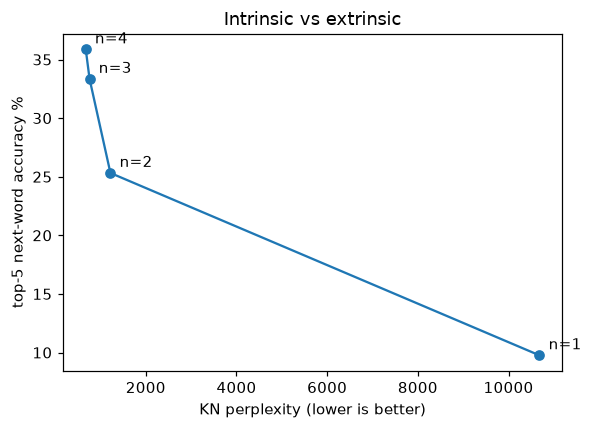

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for c in ["NWP top1", "NWP top5", "NWP top10"]:
    ax[0].plot(ext.index, 100 * ext[c], "o-", label=c.replace("NWP ", ""))
ax[0].set(title="Next-word prediction accuracy", xlabel="n", ylabel="%", xticks=[1, 2, 3, 4]); ax[0].legend()
ax[1].bar(ext.index, 100 * ext["KSS (top-5)"], color="#8172B2")
ax[1].set(title="Keystroke savings (5 suggestions)", xlabel="n", ylabel="% keystrokes saved", xticks=[1, 2, 3, 4])
for c in ["discrim. swap", "discrim. replace", "discrim. shuffle"]:
    ax[2].plot(ext.index, 100 * ext[c], "o-", label=c.replace("discrim. ", ""))
ax[2].axhline(50, ls="--", c="gray", lw=1)
ax[2].set(title="Real vs. corrupted sentence", xlabel="n", ylabel="accuracy %", xticks=[1, 2, 3, 4]); ax[2].legend()
plt.tight_layout(); plt.savefig(FIG / "extrinsic.png", bbox_inches="tight"); plt.show()

# intrinsic vs extrinsic
plt.figure(figsize=(5.5, 4))
plt.plot(pp["Kneser-Ney"], 100 * ext["NWP top5"], "o-")
for n in range(1, 5):
    plt.annotate(f"n={n}", (pp.loc[n, "Kneser-Ney"], 100 * ext.loc[n, "NWP top5"]),
                 textcoords="offset points", xytext=(6, 4))
plt.xlabel("KN perplexity (lower is better)"); plt.ylabel("top-5 next-word accuracy %")
plt.title("Intrinsic vs extrinsic"); plt.tight_layout()
plt.savefig(FIG / "intrinsic_vs_extrinsic.png", bbox_inches="tight"); plt.show()
save_results()

**Findings:** same ranking as perplexity (1 ≪ 2 < 3 < 4). Unigram = 50% on swap/shuffle (ignores order). About half the keystrokes are saved.

---
# Part 4 — Next-word suggestion
Input → last 1–2 words → candidates seen after them → Kneser-Ney probability → top 5 (word completion if the last word is unfinished). App: `app/` and the Hugging Face Space.

In [20]:
def suggest(text, n=3, k=5, lm=lm):
    """Top-k next-word suggestions for an incomplete Amharic sentence."""
    text = normalize(text)
    toks = tokenize(text)
    prefix = ""
    if text and not text[-1].isspace() and toks:   # last word still being typed
        prefix = toks.pop()
    context = toks[-(n - 1):] if n > 1 else []
    return context, prefix, lm.topk_next(context, n=n, k=k, prefix=prefix)

for q in ["ኢትዮጵያ ውስጥ የቡና ", "ኢትዮጵያ በአፍሪካ ", "አዲስ ", "ጠቅላይ ሚኒስትር ", "የኢትዮጵያ ህዝብ ", "ኢትዮጵያ ውስጥ የቡና ም"]:
    ctx, pre, s = suggest(q)
    print(f"Input: {q!r:28} context={ctx} prefix={pre!r}")
    for w, p in s:
        print(f"      {w:<14} {p:.4f}")
RESULTS["suggestions"] = {q: suggest(q)[2] for q in ["ኢትዮጵያ ውስጥ የቡና ", "ኢትዮጵያ በአፍሪካ ", "አዲስ ", "ጠቅላይ ሚኒስትር "]}

Input: 'ኢትዮጵያ ውስጥ የቡና '             context=['ውስጥ', 'የቡና'] prefix=''
      ፍጆታ            0.1227
      ዋጋ             0.0990
      የወጪ            0.0517
      ምርት            0.0395
      ግብይት           0.0216
Input: 'ኢትዮጵያ በአፍሪካ '               context=['ኢትዮጵያ', 'በአፍሪካ'] prefix=''
      ቀንድ            0.1832
      ውስጥ            0.0527
      ህብረት           0.0411
      አህጉር           0.0378
      ደረጃ            0.0353
Input: 'አዲስ '                       context=['አዲስ'] prefix=''
      አበባ            0.5035
      ዘመን            0.2488
      አበባን           0.0248
      አድማስ           0.0134
      ነገር            0.0121
Input: 'ጠቅላይ ሚኒስትር '                context=['ጠቅላይ', 'ሚኒስትር'] prefix=''
      አብይ            0.1448
      መለስ            0.1068
      ይለማርያም         0.0935
      አቢይ            0.0860
      ይለ             0.0534
Input: 'የኢትዮጵያ ህዝብ '                context=['የኢትዮጵያ', 'ህዝብ'] prefix=''
      አርበኞች          0.0415
      ነው             0.0191
      ጋር             0.0135
      ቁጥ

In [21]:
# Simulated composition: always pick the 1st suggestion (greedy) and the 2nd one
for pick in (0, 1):
    text = "ኢትዮጵያ "
    for _ in range(8):
        s = suggest(text)[2]
        if not s or s[min(pick, len(s) - 1)][0] == EOS:
            break
        text += s[min(pick, len(s) - 1)][0] + " "
    print(f"choose suggestion #{pick + 1} each time →", text.strip() + " ።")

choose suggestion #1 each time → ኢትዮጵያ ውስጥ ያለው ሁኔታ ግን ከዚህ የተለየ ነው ።
choose suggestion #2 each time → ኢትዮጵያ ነገ አማርኛ ተናጋሪ ህዝብ ላይ ከፍተኛ ተጽእኖ ያሳድራል ።


**App model:** n-grams seen < 3 times are pruned to shrink the model; the cost is measured below.

In [22]:
APP_MODEL = ROOT / "app" / "model" / "amharic_4gram_kn.npz"
APP_MODEL.parent.mkdir(parents=True, exist_ok=True)
lm.save(APP_MODEL, min_count=3)
print(f"saved {APP_MODEL.name}: {APP_MODEL.stat().st_size / 1e6:.0f} MB")
lm_small = NgramLM.load(APP_MODEL)
print("pruned model:", suggest("ኢትዮጵያ ውስጥ የቡና ", lm=lm_small)[2])
prune_cmp = pd.DataFrame([
    {"model": "full", "n": n, **E.next_word_prediction(lm, test_l, n, 5000)} for n in (2, 3, 4)] + [
    {"model": "pruned (app)", "n": n, **E.next_word_prediction(lm_small, test_l, n, 5000)} for n in (2, 3, 4)]
)[["model", "n", "top1", "top5", "mrr@10", "ms_per_query"]]
RESULTS["pruning"] = prune_cmp.to_dict("records")
display(prune_cmp.style.format({"top1": "{:.3f}", "top5": "{:.3f}", "mrr@10": "{:.3f}", "ms_per_query": "{:.1f}"}))
RESULTS["app_model_mb"] = APP_MODEL.stat().st_size / 1e6
RESULTS["runtime_minutes"] = (time.time() - T0) / 60
save_results()
print(f"Total runtime: {(time.time() - T0) / 60:.1f} min")

saved amharic_4gram_kn.npz: 122 MB


pruned model: [('ፍጆታ', 0.12265080303716551), ('ዋጋ', 0.09904301925317066), ('ምርት', 0.03308856040315082), ('ቤት', 0.01701212852592402), ('ግብይት', 0.015135413852369302)]


,model,n,top1,top5,mrr@10,ms_per_query
0,full,2,0.151,0.253,0.196,5.7
1,full,3,0.215,0.333,0.266,9.7
2,full,4,0.244,0.359,0.293,13.9
3,pruned (app),2,0.150,0.245,0.192,1.5
4,pruned (app),3,0.183,0.285,0.227,2.4
5,pruned (app),4,0.187,0.290,0.231,3.3


Total runtime: 16.1 min
